# Actividad 6. Integración de la interfaz de usuario

## Objetivo

Integrar de manera coherente el mapa 3D, la capa temática, los filtros, los
controles interactivos y el panel de información por país en una sola
experiencia. La actividad cuida la distribución de los elementos, la
sincronización de las interacciones, la usabilidad, la accesibilidad, la
capacidad de respuesta y la consistencia visual.

## Entregables

| Componente | Archivo |
|---|---|
| Capa de integración y estado de interfaz | `app/js/ui_shell.js` |
| Emisión de eventos y API pública | `app/js/app.js` |
| Estructura accesible y regiones vivas | `app/index.html` |
| Estilos de integración y diseño adaptable | `app/css/estilos.css` |
| Auditoría automática | `src/validar_ui.py` |
| Reporte de validación | `resultados/tablas/validacion_ui.csv` |
| Evidencia visual | `resultados/graficas/integracion_ui/` |

> Esta actividad **no rediseña** la apariencia: conserva la paleta, el panel
> lateral y la distribución original. Añade la capa que coordina las piezas.

## 1. Arquitectura de la integración

La interfaz se organiza en tres niveles para evitar dependencias circulares:

1. **Datos y mapa** (`capa_tematica.js`, `app.js`): calculan la capa, aplican
   filtros y dibujan el globo 3D.
2. **Orquestación** (`app.js`): emite eventos de dominio cuando cambia algo
   relevante. Ningún módulo de presentación necesita consultar el estado
   interno del mapa.
3. **Integración de interfaz** (`ui_shell.js`): escucha esos eventos,
   actualiza chips, sincronización, enlaces profundos, anuncios para lectores
   de pantalla y el buscador.

```
Filtros ──► aplicarFiltros() ──► atlas:filtros ──► chips + barra + anuncio
Mapa    ──► clic en país   ──► atlas:seleccion ──► ficha + hash + anuncio
Panel   ──► abrir/cerrar   ──► atlas:modal    ──► ayuda de foco + anuncio
Vista   ──► globo/plano    ──► atlas:proyeccion ──► persistencia + hash
Pestañas──► activarPestana ──► atlas:pestana  ──► persistencia + hash
México  ──► abrir/cerrar   ──► atlas:mexico   ──► hash + anuncio
Arranque──► datos listos    ──► atlas:listo    ──► restaurar vista
```

## 2. Preparación

Cargo las rutas del proyecto y las utilidades de validación. El notebook se
puede ejecutar desde la raíz o desde `notebooks/`.

In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.config import APP, RESULTADOS_GRAFICAS, RESULTADOS_TABLAS
import src.validar_ui as validar

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
})

PURPURA = "#4c1d95"
ROSA = "#fa8a9a"
AMARILLO = "#ffb71b"
ROJO = "#ee3e29"
GRIS = "#7a7191"

ARCHIVOS = {
    "HTML": APP / "index.html",
    "CSS": APP / "css" / "estilos.css",
    "app.js": APP / "js" / "app.js",
    "ui_shell.js": APP / "js" / "ui_shell.js",
}
for nombre, ruta in ARCHIVOS.items():
    print(f"{nombre:12s} {ruta.stat().st_size:>7,} bytes  {'OK' if ruta.exists() else 'FALTA'}")

print(f"Raíz del proyecto: {RAIZ}")
print(f"Tablas: {RESULTADOS_TABLAS}")

HTML          34,807 bytes  OK
CSS           58,786 bytes  OK
app.js        79,128 bytes  OK
ui_shell.js   28,665 bytes  OK
Raíz del proyecto: C:\Users\itzel\PROYECTO_DESASTRES
Tablas: C:\Users\itzel\PROYECTO_DESASTRES\resultados\tablas


## 3. Sincronización por eventos

La comunicación se hace con eventos personalizados sobre `document`. Así el
mapa no conoce los chips, y los chips no conocen el mapa: ambos reaccionan al
mismo contrato. Verifico que los siete eventos se emitan y se escuchen.

In [2]:
EVENTOS = [
    "atlas:filtros",
    "atlas:seleccion",
    "atlas:modal",
    "atlas:proyeccion",
    "atlas:pestana",
    "atlas:mexico",
    "atlas:listo",
]

app_js = (APP / "js" / "app.js").read_text(encoding="utf-8")
shell_js = (APP / "js" / "ui_shell.js").read_text(encoding="utf-8")
mexico_js = (APP / "js" / "mexico_estados.js").read_text(encoding="utf-8")
todo_js = app_js + "\n" + mexico_js

filas = []
for evento in EVENTOS:
    emitido = re.search(rf'(?:emitir|CustomEvent)\(\s*["\']{re.escape(evento)}["\']', todo_js)
    escuchado = f'addEventListener("{evento}"' in shell_js
    filas.append({
        "evento": evento,
        "se emite": "sí" if emitido else "no",
        "se escucha": "sí" if escuchado else "no",
    })

tabla_eventos = pd.DataFrame(filas)
assert (tabla_eventos[["se emite", "se escucha"]] == "sí").all().all()
tabla_eventos

,evento,se emite,se escucha
0,atlas:filtros,sí,sí
1,atlas:seleccion,sí,sí
2,atlas:modal,sí,sí
3,atlas:proyeccion,sí,sí
4,atlas:pestana,sí,sí
5,atlas:mexico,sí,sí
6,atlas:listo,sí,sí


## 4. Auditoría de identificadores y accesibilidad

`src/validar_ui.py` revisa de forma automática:

* IDs que el JavaScript consulta y que deben existir en el HTML.
* Duplicados, referencias `aria-controls`, `aria-labelledby` y
  `aria-describedby`.
* Botones con nombre accesible, campos etiquetados y diálogos rotulados.
* Presencia de regiones vivas, foco visible, movimiento reducido y tamaños
  táctiles.
* Contraste WCAG AA de los pares de color que se usan como texto.

In [3]:
codigo = validar.main()
assert codigo == 0, "La validación encontró errores estructurales"
print("\nAuditoría sin errores.")

Validación de interfaz: 35 comprobaciones
  Correctas: 35
  Errores: 0
  Advertencias: 0
Reporte: resultados\tablas\validacion_ui.csv

Auditoría sin errores.


In [4]:
validacion = pd.read_csv(RESULTADOS_TABLAS / "validacion_ui.csv")
resumen = (
    validacion.groupby(["categoria", "resultado"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["OK", "REVISAR"], fill_value=0)
)
resumen

resultado,OK,REVISAR
categoria,,
Accesibilidad,10,0
Contraste,12,0
Estructura,4,0
Integración,9,0


In [5]:
validacion[validacion["categoria"].isin(["Estructura", "Accesibilidad"])][
    ["comprobacion", "resultado", "detalle"]
]

,comprobacion,resultado,detalle
0,Idioma del documento declarado,OK,lang=es
1,Landmarks principales presentes,OK,"header, main, nav, aside y footer"
2,Identificadores únicos,OK,133 IDs declarados
3,Enlaces para saltar contenido,OK,2 enlaces de salto
4,Región viva para anuncios,OK,#anuncio-lector con role=status y aria-live=po...
5,Pestañas con estado y panel asociado,OK,4 pestañas
6,Paneles de pestaña etiquetados,OK,4 paneles
7,Botones con nombre accesible,OK,22 botones
8,Campos de formulario etiquetados,OK,17 campos
9,Diálogos etiquetados,OK,3 diálogos


## 5. Contraste y consistencia visual

La paleta institucional se conserva. Los pares de color que se usan como texto
superan el mínimo de 4.5:1 que exige WCAG AA para texto normal. El siguiente
gráfico resume las razones calculadas.

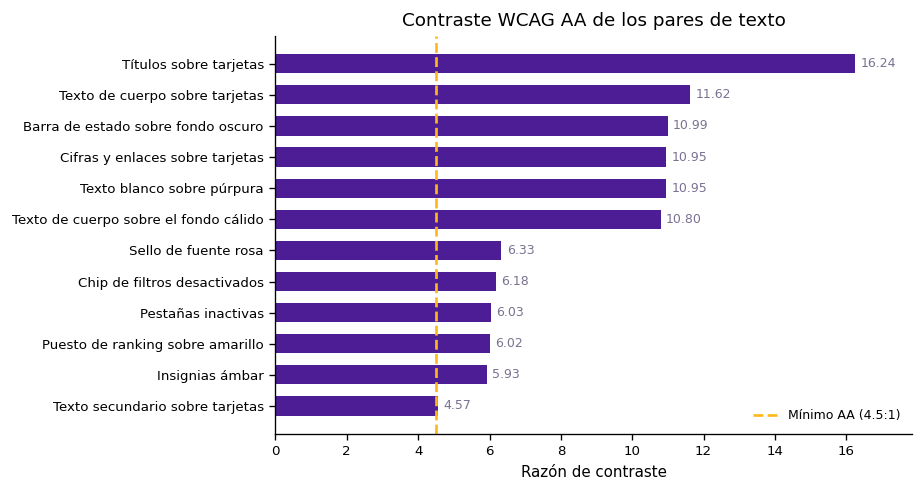

Pares verificados: 12 · mínimo: 4.57:1


In [6]:
contraste = validacion[validacion["categoria"] == "Contraste"].copy()
contraste["razon"] = (
    contraste["detalle"].str.extract(r"= ([\d.]+):1")[0].astype(float)
)
contraste = contraste.sort_values("razon")

fig, ax = plt.subplots(figsize=(7.8, 4.2))
colores = [PURPURA if valor >= 4.5 else ROJO for valor in contraste["razon"]]
ax.barh(contraste["comprobacion"], contraste["razon"], color=colores, height=0.62)
ax.axvline(4.5, color=AMARILLO, linestyle="--", linewidth=1.6, label="Mínimo AA (4.5:1)")
for posicion, valor in enumerate(contraste["razon"]):
    ax.text(valor + 0.15, posicion, f"{valor:.2f}", va="center", fontsize=7.5, color=GRIS)
ax.set_xlim(0, max(contraste["razon"]) + 1.6)
ax.set_xlabel("Razón de contraste")
ax.set_title("Contraste WCAG AA de los pares de texto")
ax.legend(loc="lower right", fontsize=7.5, frameon=False)
plt.tight_layout()

salida = RESULTADOS_GRAFICAS / "integracion_ui"
salida.mkdir(parents=True, exist_ok=True)
plt.savefig(salida / "contraste_wcag.png", bbox_inches="tight")
plt.show()

assert (contraste["razon"] >= 4.5).all()
print(f"Pares verificados: {len(contraste)} · mínimo: {contraste['razon'].min():.2f}:1")

## 6. Del filtro al mapa y al panel

El mismo cambio de filtro debe producir una sola actualización coherente:
mapa, tarjetas, panel del país y barra de sincronización. Compruebo que el
total que anuncia la interfaz coincide con `filtros.json`.

In [7]:
datos_filtros = json.loads((APP / "datos" / "filtros.json").read_text(encoding="utf-8"))
filas = [
    {"anio": fila[0], "tipo": fila[1], "eventos": fila[2], "fallecidos": fila[3],
     "afectados": fila[4], "dano_mxn": fila[5]}
    for pais in datos_filtros["datos"].values()
    for fila in pais
]
df = pd.DataFrame(filas)

total_completo = int(df["eventos"].sum())
subconjunto = df[df["anio"] >= 2010]
total_2010 = int(subconjunto["eventos"].sum())

print("Periodo completo  → " + f"Mostrando {total_completo:,} eventos · todos los tipos · 2000 – 2026")
print("Desde 2010        → " + f"Mostrando {total_2010:,} eventos · todos los tipos · 2010 – 2026")
print("\nLa barra de sincronización de la app usa exactamente estos conteos.")

por_tipo = (
    subconjunto.groupby("tipo")["eventos"].sum().sort_values(ascending=False).head(6)
)
por_tipo.to_frame("eventos_2010_2026")

Periodo completo  → Mostrando 10,907 eventos · todos los tipos · 2000 – 2026
Desde 2010        → Mostrando 6,526 eventos · todos los tipos · 2010 – 2026

La barra de sincronización de la app usa exactamente estos conteos.


,eventos_2010_2026
tipo,
Flood,2605
Storm,1882
Earthquake,423
Extreme temperature,388
Epidemic,336
Mass movement (wet),316


## 7. Enlaces profundos y persistencia

La dirección del navegador guarda la vista con cuatro parámetros. La pestaña y
la proyección también se recuerdan en `localStorage`, de modo que al volver a
abrir la aplicación se recupera el contexto.

In [8]:
plantillas = {
    "País abierto": "#pais=MEX",
    "Pestaña activa": "#pestana=filtros",
    "Vista plana": "#proyeccion=plano",
    "Mapa de México": "#mexico=1",
    "Vista combinada": "#pais=JPN&pestana=filtros&proyeccion=plano",
}

for nombre, enlace in plantillas.items():
    print(f"{nombre:18s} {enlace}")

assert "location.hash" in shell_js
assert "history.replaceState" in shell_js
assert "localStorage" in shell_js
assert "URLSearchParams" in shell_js
print("\nEnlaces profundos y persistencia conectados.")

País abierto       #pais=MEX
Pestaña activa     #pestana=filtros
Vista plana        #proyeccion=plano
Mapa de México     #mexico=1
Vista combinada    #pais=JPN&pestana=filtros&proyeccion=plano

Enlaces profundos y persistencia conectados.


## 8. Capacidad de respuesta y accesibilidad

En pantallas de hasta 900 px el panel se convierte en una hoja inferior
colapsable, con botón visible, cierre explícito y foco gestionado. La leyenda
se reubica para no tapar los controles. El resto de reglas cubre teclado,
lectores de pantalla y preferencias del sistema.

In [9]:
css = (APP / "css" / "estilos.css").read_text(encoding="utf-8")
reglas = {
    "Diseño adaptable (≤900 px)": "@media (max-width: 900px)" in css,
    "Panel móvil colapsable": "body.panel-abierto .panel" in css,
    "Tamaños táctiles": "@media (pointer: coarse)" in css,
    "Movimiento reducido": "prefers-reduced-motion" in css,
    "Foco visible": ":focus-visible" in css,
    "Contraste forzado": "forced-colors: active" in css,
}
pd.Series(reglas, name="presente").to_frame()

,presente
Diseño adaptable (≤900 px),True
Panel móvil colapsable,True
Tamaños táctiles,True
Movimiento reducido,True
Foco visible,True
Contraste forzado,True


In [10]:
atajos = {
    "/": "Buscar país",
    "1 – 4": "Cambiar de pestaña",
    "G": "Globo 3D",
    "P": "Vista plana",
    "M": "Mapa de México",
    "?": "Ayuda",
    "Esc": "Cerrar panel o diálogo",
}
pd.Series(atajos, name="acción").to_frame()

,acción
/,Buscar país
1 – 4,Cambiar de pestaña
G,Globo 3D
P,Vista plana
M,Mapa de México
?,Ayuda
Esc,Cerrar panel o diálogo


## 9. Evidencia visual

Las capturas se generan con `python -m src.capturas_ui` y documentan la
integración en escritorio y móvil.

In [11]:
carpeta = RESULTADOS_GRAFICAS / "integracion_ui"
capturas = sorted(carpeta.glob("*.png"))
if capturas:
    tabla_capturas = pd.DataFrame({
        "archivo": [ruta.name for ruta in capturas],
        "tamaño_kb": [round(ruta.stat().st_size / 1024, 1) for ruta in capturas],
    })
    display(tabla_capturas)
else:
    print("Aún no hay capturas. Ejecuta: python -m src.capturas_ui")

,archivo,tamaño_kb
0,01_escritorio_resumen.png,202.8
1,02_escritorio_filtros.png,220.1
2,03_escritorio_buscador.png,204.1
3,04_modal_pais.png,197.6
4,05_ayuda_atajos.png,255.1
5,06_movil_mapa.png,88.4
6,07_movil_panel.png,67.3
7,08_mexico_estados.png,166.7
8,contraste_wcag.png,50.2


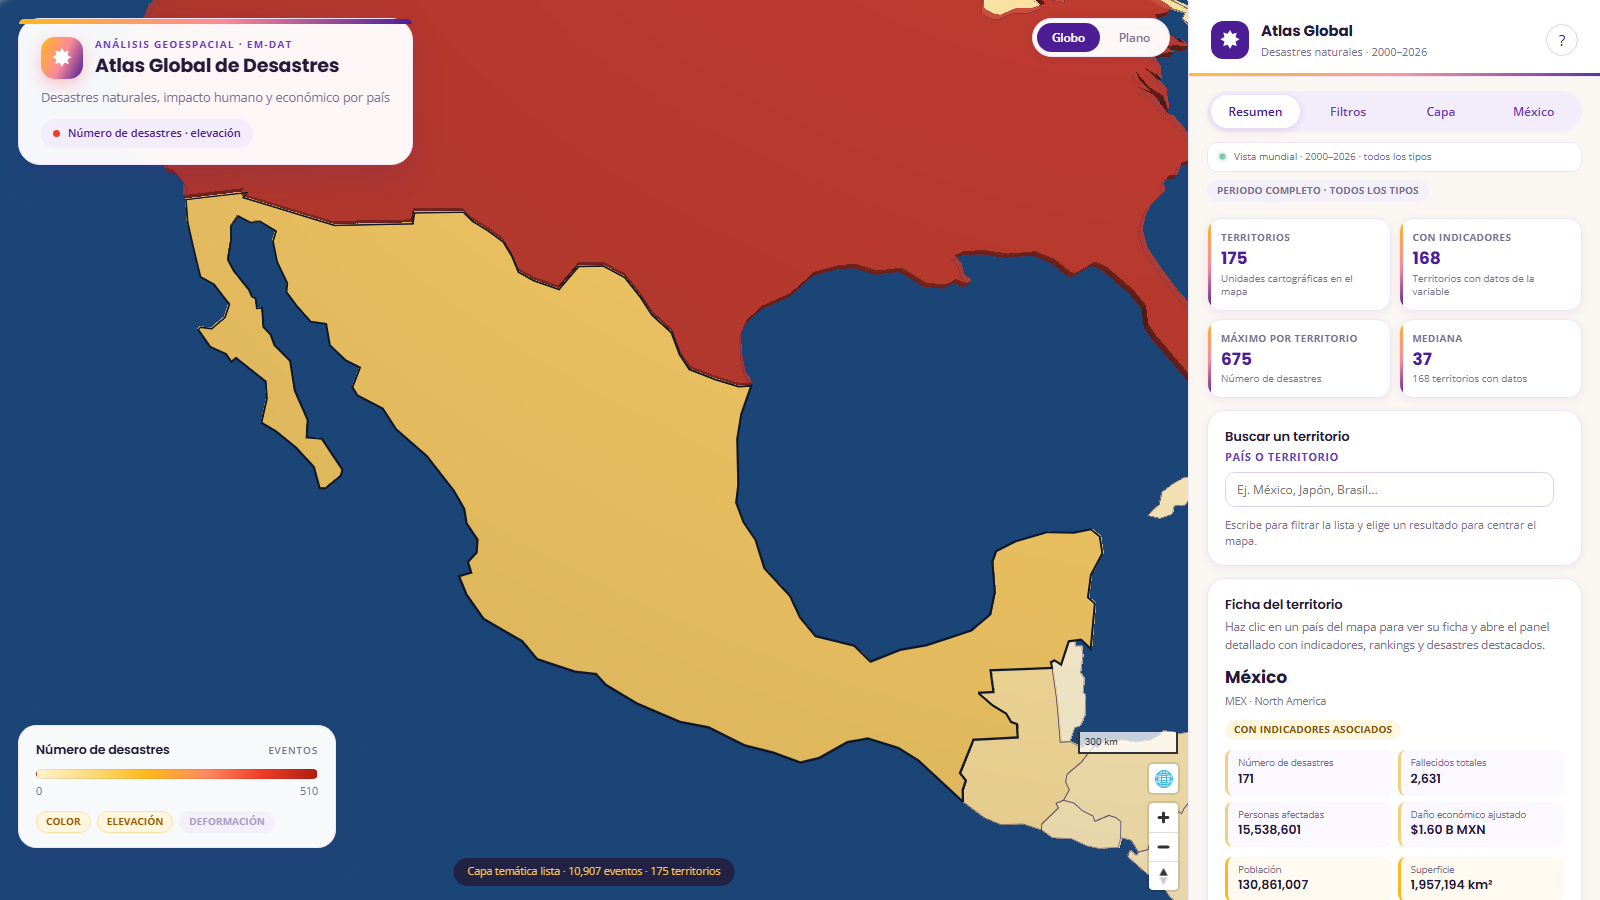

In [12]:
from IPython.display import Image, display

principal = RESULTADOS_GRAFICAS / "integracion_ui" / "01_escritorio_resumen.png"
if principal.exists():
    display(Image(filename=str(principal), width=900))
else:
    print("Captura principal pendiente.")

## 10. Conclusiones

* La interfaz queda integrada por **eventos**, no por llamadas cruzadas: el
  mapa, los filtros y los paneles comparten un contrato explícito de siete
  eventos.
* Los **filtros** actualizan mapa, tarjetas, panel del país y barra de
  sincronización; los chips permiten retirar cada filtro sin perder contexto.
* La **selección de un país** actualiza la ficha, abre el panel detallado y
  queda registrada en la dirección del navegador.
* La **accesibilidad** se comprueba automáticamente: etiquetas, roles,
  referencias ARIA, regiones vivas, foco visible, contraste y tamaños táctiles.
* La **capacidad de respuesta** convierte el panel en una hoja inferior en
  móvil, sin alterar la distribución de escritorio.
* La apariencia original se conserva: misma paleta, mismo panel lateral y
  mismos componentes visuales.

El reporte completo de las **35 comprobaciones** está en
`resultados/tablas/validacion_ui.csv`.